# Policy evaluation: TOMC, TD(λ), and True Online TD(λ)

We compare how accurately each method estimates the cost of a fixed policy, then how it helps the same SPMD optimizer improve a policy. Both games use their existing baseline rules.

The functions below are the executable experiment code from `policy_evaluation.py`, arranged in lecture-style cells. Use **Restart Kernel and Run All**. By default this notebook reads the saved five-seed results; set `RUN_EXPERIMENTS = True` to create a new run.

## Connection to the assignments and lectures

- **Assignment 2:** first visits, truncated returns, and dynamic exploration until required state/action pairs have been visited.
- **Lectures 18–19 and 22:** flatten `(s,a)` into `z`, construct `Phi`, use `Q = Phi @ theta`, and update `theta_t` with a sampled TD direction.
- **Lecture 20:** traces and averaging complete Monte Carlo replications.
- **Lecture 21 notebook:** simple NumPy functions, explicit loops, and error measured against a reference value. Its unfinished placeholders are completed here.
- **True Online TD(λ):** Dutch traces and the correction term are an additional method from van Seijen and Sutton (2014), not a claim that this formula appears in the course code.

**Target clarification:** the submitted proposal averages over the next action. Here we sample the next action from the fixed policy, matching the lecture update. For action values this is the sampled-action/Sarsa form of True Online TD(λ). These are distinct implementations; the report should use the sampled target shown below.


## Imports and configuration

In [1]:
from pathlib import Path
from functools import lru_cache
from itertools import product
from datetime import datetime
import argparse
import json
import time
import numpy as np
import numpy.linalg as la

# Locate the project when Jupyter starts in either folder.
import sys
project_dir = next((p for p in [Path.cwd(), *Path.cwd().parents]
                    if (p / 'policy_evaluation_enhancements' / 'baseline.py').exists()), None)
if project_dir is None:
    raise FileNotFoundError('Open this notebook from the Project folder or one of its subfolders.')
sys.path.insert(0, str(project_dir))
from policy_evaluation_enhancements.baseline import GridWorld
from policy_evaluation_enhancements.baseline_blackjack import Blackjack
from policy_evaluation_enhancements.utils import mirror_step, evaluate_start, write_csv, truncated_first_visit_q
project_folder = project_dir / 'policy_evaluation_enhancements'

METHODS = ['tomc', 'td_tabular', 'true_tabular', 'td_linear', 'true_linear']
LABELS = {'tomc': 'TOMC (dynamic exploration)', 'td_tabular': 'TD(λ), tabular',
          'true_tabular': 'True Online TD(λ), tabular', 'td_linear': 'TD(λ), linear',
          'true_linear': 'True Online TD(λ), linear'}
ALPHAS = [.01, .05, .1]
LAMBDAS = [.3, .6, .9]  # Nonzero trace comparison; TD(0) is tested separately.
STEP_SIZES = [.1, .5, 1.]
TEST_SEEDS = [101, 202, 303, 404, 505]


## Features: z = s * N_ACTIONS + a, Q = Phi @ theta

In [2]:
def feature_matrix(env, representation):
    n_Z = env.n_states * env.n_actions
    if representation == 'tabular':
        return np.eye(n_Z)
    s = np.arange(env.n_states)
    if isinstance(env, GridWorld):
        u, v = (s // env.cols)/(env.rows-1), (s % env.cols)/(env.cols-1)
        base = np.column_stack([np.ones(len(s)), u, v, u*u, v*v, u*v,
                                np.isin(s, env.goals), np.isin(s, env.hazards)])
    else:
        player, dealer = env.decode(s)
        u, v = (player-4)/7, (dealer-2)/3
        base = np.column_stack([np.ones(len(s)), u, v, u*u, v*v, u*v])
    base /= la.norm(base, axis=1, keepdims=True)
    d = base.shape[1]
    Phi = np.zeros((n_Z, d*env.n_actions))
    for s in range(env.n_states):
        for a in range(env.n_actions):
            z = s*env.n_actions+a
            Phi[z, a*d:(a+1)*d] = base[s]
    return Phi


## TD update directions (Lecture 19/22 sign convention)

For each sampled transition, use $\delta_t=c_t+\gamma Q(s_{t+1},a_{t+1})-Q(s_t,a_t)$. A terminal transition has a zero next prediction. Standard TD(λ) uses accumulating traces. True Online TD(λ) uses Dutch traces and an extra correction. Tabular features are an identity matrix; compact linear features share parameters across states.

In [3]:
def td_step(theta_t, e_t, Q_old, Phi_t, Phi_t_next, cost, gamma, eta, lam, true_online):
    Q_t = float(Phi_t @ theta_t)
    Q_next = float(Phi_t_next @ theta_t)
    delta_t = cost + gamma*Q_next - Q_t
    if true_online:
        trace_dot_phi = float(e_t @ Phi_t)  # Old trace, before changing it.
        e_t *= gamma*lam
        e_t += (1-eta*gamma*lam*trace_dot_phi)*Phi_t
        correction = Q_t-Q_old
        tilde_F_t = -(delta_t+correction)*e_t + correction*Phi_t
    else:
        e_t *= gamma*lam
        e_t += Phi_t
        tilde_F_t = -delta_t*e_t
    theta_t -= eta*tilde_F_t
    return Q_next  # Pre-update next prediction, needed by True Online TD.


## Online sampling and first-visit TOMC

In [4]:
def initial_state(env, rng):
    if isinstance(env, Blackjack):
        player = int(rng.integers(2, 6)) + int(rng.integers(2, 6))
        dealer = int(rng.integers(2, 6))
        return (player-4)*4+dealer-2
    return env.start


def sample_action(cumulative_pi, s_t, rng):
    return min(int(np.searchsorted(cumulative_pi[s_t], rng.random(), side='right')),
               cumulative_pi.shape[1]-1)


def tomc_start(pi, gamma):
    unpi = (1-gamma)/pi.shape[1]
    required = pi >= unpi
    return dict(first_time_sa=np.full(pi.shape, -1, dtype=int), costs=[], terminals=[],
                required=required, remaining=int(required.sum()), target=None,
                coverage_time=None, complete=False, threshold=unpi)


def tomc_observe(data, s_t, a_t, cost, terminal, T):
    t = len(data['costs'])
    data['costs'].append(cost)
    data['terminals'].append(terminal)
    if data['first_time_sa'][s_t, a_t] == -1:
        data['first_time_sa'][s_t, a_t] = t
        if data['required'][s_t, a_t]:
            data['remaining'] -= 1
            if data['remaining'] == 0:
                data['coverage_time'] = t+1
                data['target'] = t+T
    data['complete'] = data['target'] is not None and t+1 >= data['target']
    return data['complete']


## Exact reference calculations: diagnostic use only, like the lecture demo

In [5]:
def reference_model(env):
    P = np.zeros((env.n_states, env.n_states, env.n_actions))  # [next, current, action]
    c = np.zeros((env.n_states, env.n_actions))
    if isinstance(env, GridWorld):
        directions = [(-1, 0), (1, 0), (0, -1), (0, 1)]
        for s in range(env.n_states):
            special = s in env.goals or s in env.hazards
            reset = env.reset_probability if special else 0.
            c[s] = 0. if s in env.goals else 1. if s in env.hazards else .2
            for a in range(env.n_actions):
                P[env.start, s, a] += reset
                for actual, (dr, dc) in enumerate(directions):
                    prob = env.intended_probability if a == actual else (1-env.intended_probability)/3
                    row = min(env.rows-1, max(0, s//env.cols+dr))
                    col = min(env.cols-1, max(0, s%env.cols+dc))
                    P[row*env.cols+col, s, a] += (1-reset)*prob
    else:
        @lru_cache(None)
        def dealer_cost(player, total):
            if total >= 9:
                return -1. if total > 11 else float(np.sign(total-player))
            return sum(dealer_cost(player, total+card) for card in range(2, 6))/4
        for s in range(env.n_states):
            player, dealer = map(int, env.decode(s))
            c[s, 0] = sum(dealer_cost(player, dealer+card) for card in range(2, 6))/4
            for card in range(2, 6):
                if player+card > 11:
                    c[s, 1] += .25
                else:
                    P[int(env.encode(player+card, dealer)), s, 1] += .25
    return P, c


def exact_policy_value(P, c, pi, gamma):
    P_pi = np.einsum('nsa,sa->sn', P, pi)
    c_pi = np.sum(c*pi, axis=1)
    V_pi = la.solve(np.eye(len(pi))-gamma*P_pi, c_pi)
    Q_pi = c + gamma*np.einsum('nsa,n->sa', P, V_pi)
    return V_pi, Q_pi


def optimal_value(P, c, gamma):
    V = np.zeros(len(c))
    for _ in range(10000):
        Q = c + gamma*np.einsum('nsa,n->sa', P, V)
        V_next = Q.min(axis=1)
        if np.max(abs(V_next-V)) < 1e-12:
            return V_next
        V = V_next
    raise RuntimeError('Reference value iteration did not converge')


def stationary_weights(env, P, pi):
    # Blackjack has terminal transitions; the observation stream restarts with
    # a new deal. The value reference above does NOT bootstrap through a deal.
    P_pi = np.einsum('nsa,sa->sn', P, pi)
    reset_distribution = np.zeros(env.n_states)
    if isinstance(env, Blackjack):
        for card1, card2, dealer in product(range(2, 6), repeat=3):
            reset_distribution[int(env.encode(card1+card2, dealer))] += 1/64
    else:
        reset_distribution[env.start] = 1.
    P_stream = P_pi + (1-P_pi.sum(axis=1))[:, None]*reset_distribution
    A = P_stream.T-np.eye(env.n_states)
    A[-1] = 1.
    b = np.zeros(env.n_states); b[-1] = 1.
    nu = la.solve(A, b)
    if np.min(nu) < -1e-10 or not np.allclose(nu @ P_stream, nu, atol=1e-10):
        raise ValueError('Invalid diagnostic stationary distribution')
    nu = np.maximum(nu, 0); nu /= nu.sum()
    return nu[:, None]*pi


## Fixed-policy evaluation with equal observation budgets

In [6]:
def evaluate_fixed(env, method, alpha, lam, budget, checkpoints, seed, Q_pi, w, T=100, paths=None):
    pi = np.full((env.n_states, env.n_actions), 1/env.n_actions)
    cumulative = pi.cumsum(axis=1)
    rng = np.random.default_rng(seed)
    s_t = initial_state(env, rng)
    a_t = sample_action(cumulative, s_t, rng)
    checkpoints = set(checkpoints)
    records = []
    completed = 0
    Q_est = np.zeros_like(pi)
    if method == 'tomc':
        data = tomc_start(pi, env.gamma)
    else:
        representation = 'tabular' if method.endswith('tabular') else 'linear'
        Phi = feature_matrix(env, representation)
        theta_t = np.zeros(Phi.shape[1]); e_t = np.zeros_like(theta_t)
        zero = np.zeros_like(theta_t); Q_old = 0.
    for t in range(1, budget+1):
        if paths is None:
            s_next, cost, terminal = env.step_one(s_t, a_t, rng)
            next_state = initial_state(env, rng) if terminal else s_next
            a_next = sample_action(cumulative, next_state, rng)
        else:
            s_t, a_t, cost, s_next, a_next, terminal = paths[t-1]
            next_state = s_next
        if method == 'tomc':
            if tomc_observe(data, s_t, a_t, cost, terminal, T):
                Q_round = truncated_first_visit_q(data, pi, env.gamma, T, data['threshold'])
                completed += 1
                Q_est += (Q_round-Q_est)/completed  # Average complete replications (Lecture 20).
                data = tomc_start(pi, env.gamma)
        else:
            z_t, z_next = s_t*env.n_actions+a_t, s_next*env.n_actions+a_next
            Phi_next = zero if terminal else Phi[z_next]
            Q_old = td_step(theta_t, e_t, Q_old, Phi[z_t], Phi_next, cost,
                            env.gamma, alpha, lam, method.startswith('true'))
            if terminal:
                e_t.fill(0); Q_old = 0.
        s_t, a_t = next_state, a_next
        if t in checkpoints:
            if method != 'tomc':
                Q_est = (Phi@theta_t).reshape(pi.shape)
            ready = method != 'tomc' or completed > 0
            err = Q_est-Q_pi
            records.append(dict(observations=t, weighted_error=float(np.sqrt(np.sum(w*err*err))) if ready else float('nan'),
                                uniform_rmse=float(np.sqrt(np.mean(err*err))) if ready else float('nan'),
                                estimate_ready=ready, completed_rounds=completed,
                                pending_pairs=data['remaining'] if method=='tomc' else 0))
    return Q_est, records


def fixed_training_data(env, budget, seed):
    rng = np.random.default_rng(seed)
    pi = np.full((env.n_states, env.n_actions), 1/env.n_actions)
    cumulative = pi.cumsum(axis=1)
    s_t = initial_state(env, rng); a_t = sample_action(cumulative, s_t, rng)
    data = []
    for _ in range(budget):
        s_next, cost, terminal = env.step_one(s_t, a_t, rng)
        next_state = initial_state(env, rng) if terminal else s_next
        a_next = sample_action(cumulative, next_state, rng)
        data.append((s_t, a_t, cost, s_next, a_next, terminal))
        s_t, a_t = next_state, a_next
    return data


## Policy improvement: the SAME baseline mirror step for every evaluator

In [7]:
def run_control(env, method, alpha, lam, budget, checkpoints, seed, step_size,
                eval_steps, P, c, V_star, T=100, score_rollouts=64):
    rng = np.random.default_rng(seed)
    score_rng = np.random.default_rng(seed+100000)
    pi = np.full((env.n_states, env.n_actions), 1/env.n_actions)
    cumulative = pi.cumsum(axis=1)
    s_t = initial_state(env, rng); a_t = sample_action(cumulative, s_t, rng)
    s0 = env.start if isinstance(env, GridWorld) else int(env.encode(env.evaluation_total, env.evaluation_dealer))
    checkpoints = set(checkpoints)
    updates = score_total = completed_rounds = 0
    records = []
    if method == 'tomc':
        data = tomc_start(pi, env.gamma)
    else:
        Phi = feature_matrix(env, 'tabular' if method.endswith('tabular') else 'linear')
        theta_t = np.zeros(Phi.shape[1]); e_t = np.zeros_like(theta_t)
        zero = np.zeros_like(theta_t); Q_old = 0.

    def record(t):
        nonlocal score_total
        V, _ = exact_policy_value(P, c, pi, env.gamma)
        # The project also asks for sampled V and observations per iteration.
        estimate, stderr, n_score = evaluate_start(env, pi, score_rollouts,
                                                  100 if isinstance(env, GridWorld) else 8, score_rng)
        score_total += n_score
        gap = float(V[s0]-V_star[s0])
        if gap < -1e-9:
            raise AssertionError('Negative optimality gap: reference inconsistency')
        records.append(dict(observations=t, policy_updates=updates, exact_value=float(V[s0]),
                            optimal_value=float(V_star[s0]), gap=max(0., gap), estimated_value=estimate,
                            value_standard_error=stderr, validation_observations=n_score,
                            cumulative_validation_observations=score_total,
                            total_observations=t+score_total,
                            pending_pairs=data['remaining'] if method=='tomc' else 0,
                            completed_rounds=completed_rounds))
    record(0)
    for t in range(1, budget+1):
        s_next, cost, terminal = env.step_one(s_t, a_t, rng)
        next_state = initial_state(env, rng) if terminal else s_next
        a_next = sample_action(cumulative, next_state, rng)
        update_now = False
        if method == 'tomc':
            if tomc_observe(data, s_t, a_t, cost, terminal, T):
                Q_est = truncated_first_visit_q(data, pi, env.gamma, T, data['threshold'])
                completed_rounds += 1
                update_now = True
        else:
            z_t = s_t*env.n_actions+a_t
            z_next = s_next*env.n_actions+a_next
            Q_old = td_step(theta_t, e_t, Q_old, Phi[z_t], zero if terminal else Phi[z_next],
                            cost, env.gamma, alpha, lam, method.startswith('true'))
            if terminal:
                e_t.fill(0); Q_old = 0.
            if t % eval_steps == 0:
                Q_est = (Phi@theta_t).reshape(pi.shape)
                update_now = True
        if update_now:
            # Sole policy optimizer. No entropy penalty or alternate divergence.
            pi = mirror_step(pi, Q_est, step_size)
            cumulative = pi.cumsum(axis=1)
            updates += 1
            if method == 'tomc':
                data = tomc_start(pi, env.gamma)
            else:
                # Carry estimates across policies, but never carry old traces.
                e_t.fill(0); Q_old = 0.
            a_next = sample_action(cumulative, next_state, rng)
            # Record EVERY policy update, not just plotting checkpoints.
            record(t)
        s_t, a_t = next_state, a_next
        if t in checkpoints and (not records or records[-1]['observations'] != t):
            record(t)
    return records


## Tuning and five-seed experiments

In [8]:
def run_experiments(output, quick=False, seeds=None):
    output = Path(output).resolve()
    output.mkdir(parents=True, exist_ok=False)
    seeds = TEST_SEEDS if seeds is None else seeds
    settings = {
        'gridworld': dict(env=GridWorld(), fixed=1200000, control=2400000, eval_steps=10000, horizons=[40, 70, 100]),
        'blackjack': dict(env=Blackjack(), fixed=40000, control=120000, eval_steps=500, horizons=[2, 3, 4])}
    if quick:
        settings['gridworld'].update(fixed=4000, control=10000, eval_steps=1000)
        settings['blackjack'].update(fixed=1000, control=2000, eval_steps=200)
    fixed_rows, control_rows, tuning_rows, selected_rows, reference_rows = [], [], [], [], []
    for name, setting in settings.items():
        env = setting['env']
        P, c = reference_model(env)
        pi_uniform = np.full((env.n_states, env.n_actions), 1/env.n_actions)
        V_pi, Q_pi = exact_policy_value(P, c, pi_uniform, env.gamma)
        V_star = optimal_value(P, c, env.gamma)
        w = stationary_weights(env, P, pi_uniform)
        s0 = env.start if name=='gridworld' else int(env.encode(env.evaluation_total, env.evaluation_dealer))
        residual = np.max(abs(V_star-np.min(c+env.gamma*np.einsum('nsa,n->sa', P, V_star), axis=1)))
        reference_rows.append(dict(environment=name, uniform_value=float(V_pi[s0]),
                                   optimal_value=float(V_star[s0]), bellman_residual=float(residual)))
        np.savez(output/f'{name}_diagnostic_reference.npz', P=P, c=c, Q_pi=Q_pi, w=w, V_star=V_star)
        # Tune using 10% of the full policy-improvement budget. Report this
        # separately from the smaller fixed-policy experiment, never hide it.
        tune_budget = setting['control']//10
        data = fixed_training_data(env, tune_budget, 17)
        chosen = {}
        for method in METHODS[1:]:
            candidates = []
            for alpha, lam in product(ALPHAS, LAMBDAS):
                _, history = evaluate_fixed(env, method, alpha, lam, tune_budget, [tune_budget],
                                             17, Q_pi, w, paths=data)
                score = history[-1]['weighted_error']
                row = dict(environment=name, stage='TD trace tuning', method=method, alpha=alpha,
                           lam=lam, horizon=0, step_size=0., observations=tune_budget,
                           score=score, completed_updates=0, eligible=True)
                tuning_rows.append(row); candidates.append(row)
            chosen[method] = min(candidates, key=lambda r:r['score'])
            # TD(0) is a separate ablation: retain it even when it does better.
            for alpha in ALPHAS:
                _, history = evaluate_fixed(env, method, alpha, 0., tune_budget, [tune_budget],
                                             17, Q_pi, w, paths=data)
                tuning_rows.append(dict(environment=name, stage='TD(0) ablation', method=method, alpha=alpha,
                                         lam=0., horizon=0, step_size=0., observations=tune_budget,
                                         score=history[-1]['weighted_error'], completed_updates=0, eligible=True))
            print(name, method, 'selected alpha/lambda', chosen[method]['alpha'], chosen[method]['lam'], flush=True)
        # TOMC tunes the truncation length, using the same fixed-policy data.
        tomc_candidates = []
        for T in setting['horizons']:
            _, history = evaluate_fixed(env, 'tomc', 0., 0., tune_budget, [tune_budget], 17, Q_pi, w, T, data)
            row = dict(environment=name, stage='TOMC horizon tuning', method='tomc', alpha=0., lam=0.,
                       horizon=T, step_size=0., observations=tune_budget, score=history[-1]['weighted_error'],
                       completed_updates=0, eligible=history[-1]['estimate_ready'])
            tomc_candidates.append(row); tuning_rows.append(row)
        eligible = [r for r in tomc_candidates if r['eligible']]
        T = min(eligible, key=lambda r:r['score'])['horizon'] if eligible else max(setting['horizons'])
        horizon_status = 'tuned' if eligible else 'fallback: no complete TOMC coverage in tuning'
        # Tune a common SPMD step size using ONLY the baseline, then freeze it
        # across every evaluation method. Exact scoring does not train policies.
        spmd_candidates = []
        for eta in STEP_SIZES:
            history = run_control(env, 'tomc', 0., 0., tune_budget, [tune_budget], 17,
                                  eta, setting['eval_steps'], P, c, V_star, T, score_rollouts=32)
            last = history[-1]
            row = dict(environment=name, stage='shared SPMD tuning', method='tomc', alpha=0., lam=0.,
                       horizon=T, step_size=eta, observations=tune_budget, score=last['gap'],
                       completed_updates=last['policy_updates'], eligible=last['policy_updates']>0)
            spmd_candidates.append(row); tuning_rows.append(row)
        eligible = [r for r in spmd_candidates if r['eligible']]
        step_size = min(eligible, key=lambda r:r['score'])['step_size'] if eligible else .5
        step_status = 'tuned' if eligible else 'fallback: no completed baseline policy update in tuning'
        selected_rows.append(dict(environment=name, method='tomc', alpha=0., lam=0., horizon=T,
                                  spmd_step_size=step_size, horizon_status=horizon_status, spmd_status=step_status))
        for method in METHODS[1:]:
            selected_rows.append(dict(environment=name, method=method, alpha=chosen[method]['alpha'],
                                      lam=chosen[method]['lam'], horizon=T, spmd_step_size=step_size,
                                      horizon_status=horizon_status, spmd_status=step_status))
        write_csv(output/'tuning.csv', tuning_rows)
        write_csv(output/'selected_settings.csv', selected_rows)
        print(name, 'TOMC T=', T, horizon_status, '; common SPMD step=', step_size, step_status, flush=True)
        fixed_checkpoints = np.unique(np.linspace(max(1, setting['fixed']//100), setting['fixed'], 51, dtype=int))
        control_checkpoints = np.unique(np.linspace(0, setting['control'], 51, dtype=int))
        # Each fixed-policy method sees the identical stream at the same seed.
        for seed in seeds:
            data = fixed_training_data(env, setting['fixed'], seed)
            for method in METHODS:
                alpha, lam = (0., 0.) if method=='tomc' else (chosen[method]['alpha'], chosen[method]['lam'])
                _, history = evaluate_fixed(env, method, alpha, lam, setting['fixed'], fixed_checkpoints,
                                             seed, Q_pi, w, T, data)
                fixed_rows.extend(dict(environment=name, method=method, seed=seed, **row) for row in history)
            write_csv(output/'fixed_policy.csv', fixed_rows)
            print(name, 'fixed-policy seed', seed, 'done', flush=True)
        # Control policies differ, so each independently samples its own policy.
        # TOMC stalls do not stop another evaluator. Every run uses the full cap.
        for seed in seeds:
            for method in METHODS:
                alpha, lam = (0., 0.) if method=='tomc' else (chosen[method]['alpha'], chosen[method]['lam'])
                history = run_control(env, method, alpha, lam, setting['control'], control_checkpoints,
                                      seed, step_size, setting['eval_steps'], P, c, V_star, T)
                previous = 0
                for row in history:
                    row['training_observations_since_log'] = row['observations']-previous
                    previous = row['observations']
                    row['plot_checkpoint'] = row['observations'] in control_checkpoints
                    control_rows.append(dict(environment=name, method=method, seed=seed, **row))
                write_csv(output/'policy_improvement.csv', control_rows)
                print(name, 'control', seed, method, 'updates',history[-1]['policy_updates'],
                      'gap',round(history[-1]['gap'],6), 'pending pairs', history[-1]['pending_pairs'], flush=True)
        write_csv(output/'references.csv', reference_rows)
    config = dict(test_seeds=seeds, tuning_seed=17, alphas=ALPHAS, nonzero_lambdas=LAMBDAS,
                  td0_ablation=True, policy_update='utils.mirror_step: unchanged Euclidean SPMD',
                  environments={name:{k:v for k,v in s.items() if k!='env'} for name,s in settings.items()},
                  tuning_budget='10% of each full control budget per candidate; cached fixed-policy streams reused across candidates',
                  primary_error='sqrt(sum(nu_pi(s)*pi(a|s)*(Q_est-Q_pi)^2)), exact diagnostic reference',
                  sampling='continuous online paths; no stationary-distribution oracle or forced starts',
                  weighting='stationary weights are diagnostic only; blackjack stream resets after terminal hands',
                  control_td='warm-start theta across policy updates; reset traces and old prediction',
                  baseline_fixed='average all completed coverage rounds; no estimate until first complete round',
                  baseline_control='fresh first-visit estimate after each coverage round; incomplete rounds keep policy unchanged',
                  validation='separate sampled V recorded at every policy update and plotting checkpoint',
                  plotting='training observations on x axis; validation observations reported separately',
                  quick=quick, numpy_version=np.__version__)
    (output/'config.json').write_text(json.dumps(config, indent=2)+'\n')
    make_plots(output)
    return output


## Plotting: two environments, five curves, across-seed standard errors

In [9]:
def read_rows(path):
    import csv
    return list(csv.DictReader(Path(path).open()))


def make_plots(output):
    import matplotlib
    matplotlib.use('Agg')
    import matplotlib.pyplot as plt
    output = Path(output)
    plt.style.use('ggplot')
    colors = ['#e66b26', '#2670b8', '#002f67', '#47a88b', '#006447']
    styles = ['-', '--', '-', '--', '-']
    for filename, metric, ylabel, title, artifact in [
        ('fixed_policy.csv', 'weighted_error', 'Weighted action-value error',
         'Policy evaluation under a fixed uniform policy', 'policy_evaluation_error'),
        ('fixed_policy.csv', 'uniform_rmse', 'Uniform action-value RMSE',
         'Supplement: error across all state/action pairs', 'policy_evaluation_uniform_error'),
        ('policy_improvement.csv', 'gap', 'Gap to optimal cost',
         'Online policy improvement: same Euclidean SPMD, different evaluators', 'policy_evaluation_policy_gap')]:
        rows = read_rows(output/filename)
        fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
        for ax, name in zip(axes, ['gridworld','blackjack']):
            seeds = sorted({r['seed'] for r in rows if r['environment']==name})
            scale = 1e6 if name=='gridworld' else 1e3
            for method, color, style in zip(METHODS, colors, styles):
                data = [r for r in rows if r['environment']==name and r['method']==method
                        and (filename=='fixed_policy.csv' or r['plot_checkpoint']=='True')]
                xs = sorted({int(r['observations']) for r in data})
                means, errors = [], []
                for x in xs:
                    values = [float(r[metric]) for r in data if int(r['observations'])==x]
                    # No survivor-only mean: wait until ALL seeds have an estimate.
                    if len(values)!=len(seeds) or not np.isfinite(values).all():
                        means.append(np.nan); errors.append(np.nan)
                    else:
                        means.append(float(np.mean(values)))
                        errors.append(float(np.std(values,ddof=1)/np.sqrt(len(values))) if len(values)>1 else 0.)
                xs = np.asarray(xs)/scale
                means, errors = np.asarray(means), np.asarray(errors)
                ax.plot(xs, means, color=color, linestyle=style, linewidth=2, label=LABELS[method])
                ax.fill_between(xs, np.maximum(0,means-errors), means+errors, color=color, alpha=.15)
            ax.set(title=f'{"GridWorld" if name=="gridworld" else "Blackjack"} — online sampling',
                   xlabel=f'Training environment steps ({"millions" if scale==1e6 else "thousands"})', ylabel=ylabel)
            ax.set_ylim(bottom=0)
            if filename=='fixed_policy.csv':
                ax.text(.02,.97,'TOMC shown only after all seeds finish first coverage',transform=ax.transAxes,
                        va='top',fontsize=8)
        handles, labels = axes[0].get_legend_handles_labels()
        fig.legend(handles,labels,loc='lower center',ncol=3,frameon=False,fontsize=9)
        fig.suptitle(f'{title}\nMean of {len(seeds)} test seeds; shaded band = ±1 standard error',fontsize=12)
        fig.tight_layout(rect=[0,.12,1,.90])
        for suffix in ['png','pdf']:
            fig.savefig(output/f'{artifact}.{suffix}',dpi=180,bbox_inches='tight')
        plt.close(fig)
    summarize_results(output)


def summarize_results(output):
    output = Path(output)
    result = []
    for filename, metric in [('fixed_policy.csv','weighted_error'),('fixed_policy.csv','uniform_rmse'),
                              ('policy_improvement.csv','gap')]:
        rows = read_rows(output/filename)
        for name,method in product(['gridworld','blackjack'],METHODS):
            selected = [r for r in rows if r['environment']==name and r['method']==method]
            seeds = sorted({r['seed'] for r in selected})
            finals = [max([r for r in selected if r['seed']==seed],key=lambda r:int(r['observations'])) for seed in seeds]
            values = np.array([float(r[metric]) for r in finals])
            result.append(dict(environment=name, method=method, metric=metric,
                               mean=float(np.mean(values)), standard_error=float(np.std(values,ddof=1)/np.sqrt(len(values))) if len(values)>1 else 0.,
                               seeds=len(seeds), observations=int(finals[0]['observations']),
                               unavailable_seeds=int((~np.isfinite(values)).sum())))
    write_csv(output/'summary.csv', result)


## Run or load the experiment

Five test seeds are separate from tuning seed 17. All methods receive the same number of training observations. Fixed-policy methods replay the same trajectory; during policy improvement each method samples its own evolving policy.

Tuning uses 10% of the **control** budget per candidate, not 10% of the shorter fixed-policy budget. Nonzero λ values are tuned for the trace comparison; TD(0) scores are retained separately in `tuning.csv`. GridWorld TOMC did not complete coverage in the tuning budget, so its horizon and the shared SPMD step are explicitly marked as fallback defaults. Do not describe them as successfully tuned.


In [10]:
RUN_EXPERIMENTS = False
QUICK_TEST = False
results = project_folder / 'policy_eval_results' / 'lecture_aligned_five_seed'
if RUN_EXPERIMENTS:
    results = project_folder / 'policy_eval_results' / ('lecture_aligned_' + datetime.now().strftime('%Y%m%d_%H%M%S'))
    run_experiments(results, quick=QUICK_TEST, seeds=[101, 202] if QUICK_TEST else None)
if not (results / 'summary.csv').exists():
    raise FileNotFoundError('The saved run is incomplete. Wait for it to finish or set RUN_EXPERIMENTS = True.')
print('Results:', results)
for row in read_rows(results / 'selected_settings.csv'):
    print(row)


Results: /Users/anjilabudathoki/Downloads/UTK Documents/Fall_2026_Course/IE692/Project/policy_evaluation_enhancements/policy_eval_results/lecture_aligned_five_seed
{'environment': 'gridworld', 'method': 'tomc', 'alpha': '0.0', 'lam': '0.0', 'horizon': '100', 'spmd_step_size': '0.5', 'horizon_status': 'fallback: no complete TOMC coverage in tuning', 'spmd_status': 'fallback: no completed baseline policy update in tuning'}
{'environment': 'gridworld', 'method': 'td_tabular', 'alpha': '0.1', 'lam': '0.9', 'horizon': '100', 'spmd_step_size': '0.5', 'horizon_status': 'fallback: no complete TOMC coverage in tuning', 'spmd_status': 'fallback: no completed baseline policy update in tuning'}
{'environment': 'gridworld', 'method': 'true_tabular', 'alpha': '0.1', 'lam': '0.9', 'horizon': '100', 'spmd_step_size': '0.5', 'horizon_status': 'fallback: no complete TOMC coverage in tuning', 'spmd_status': 'fallback: no completed baseline policy update in tuning'}
{'environment': 'gridworld', 'method': 

## Results

The first plot measures evaluation error under a fixed uniform policy, weighted by how often the policy visits each pair. The second measures the gap to optimal cost during policy improvement. They answer different questions. Exact models are used only to score estimates and policies, never to generate learning targets.

Bands show ±1 standard error across five seeds. TOMC has no completed estimate before initial coverage, so its evaluation curve begins only when all seeds have a completed estimate. Its control policy remains unchanged while waiting for coverage. Separate sampled validation observations are recorded in the CSV and excluded from the training-step axis.


In [11]:
for row in read_rows(results / 'summary.csv'):
    print(f"{row['environment']:10s} {row['method']:12s} {row['metric']:15s} "
          f"{float(row['mean']):.6f} +/- {float(row['standard_error']):.6f}")


gridworld  tomc         weighted_error  0.176373 +/- 0.025318
gridworld  td_tabular   weighted_error  0.055209 +/- 0.005088
gridworld  true_tabular weighted_error  0.054716 +/- 0.004391
gridworld  td_linear    weighted_error  0.119090 +/- 0.008435
gridworld  true_linear  weighted_error  0.131906 +/- 0.009473
blackjack  tomc         weighted_error  0.082080 +/- 0.003716
blackjack  td_tabular   weighted_error  0.105267 +/- 0.006956
blackjack  true_tabular weighted_error  0.105267 +/- 0.006956
blackjack  td_linear    weighted_error  0.182728 +/- 0.004328
blackjack  true_linear  weighted_error  0.182738 +/- 0.004327
gridworld  tomc         uniform_rmse    0.203646 +/- 0.011154
gridworld  td_tabular   uniform_rmse    0.176756 +/- 0.013740
gridworld  true_tabular uniform_rmse    0.177970 +/- 0.013709
gridworld  td_linear    uniform_rmse    0.170784 +/- 0.002530
gridworld  true_linear  uniform_rmse    0.176252 +/- 0.003400
blackjack  tomc         uniform_rmse    0.080209 +/- 0.003292
blackjac

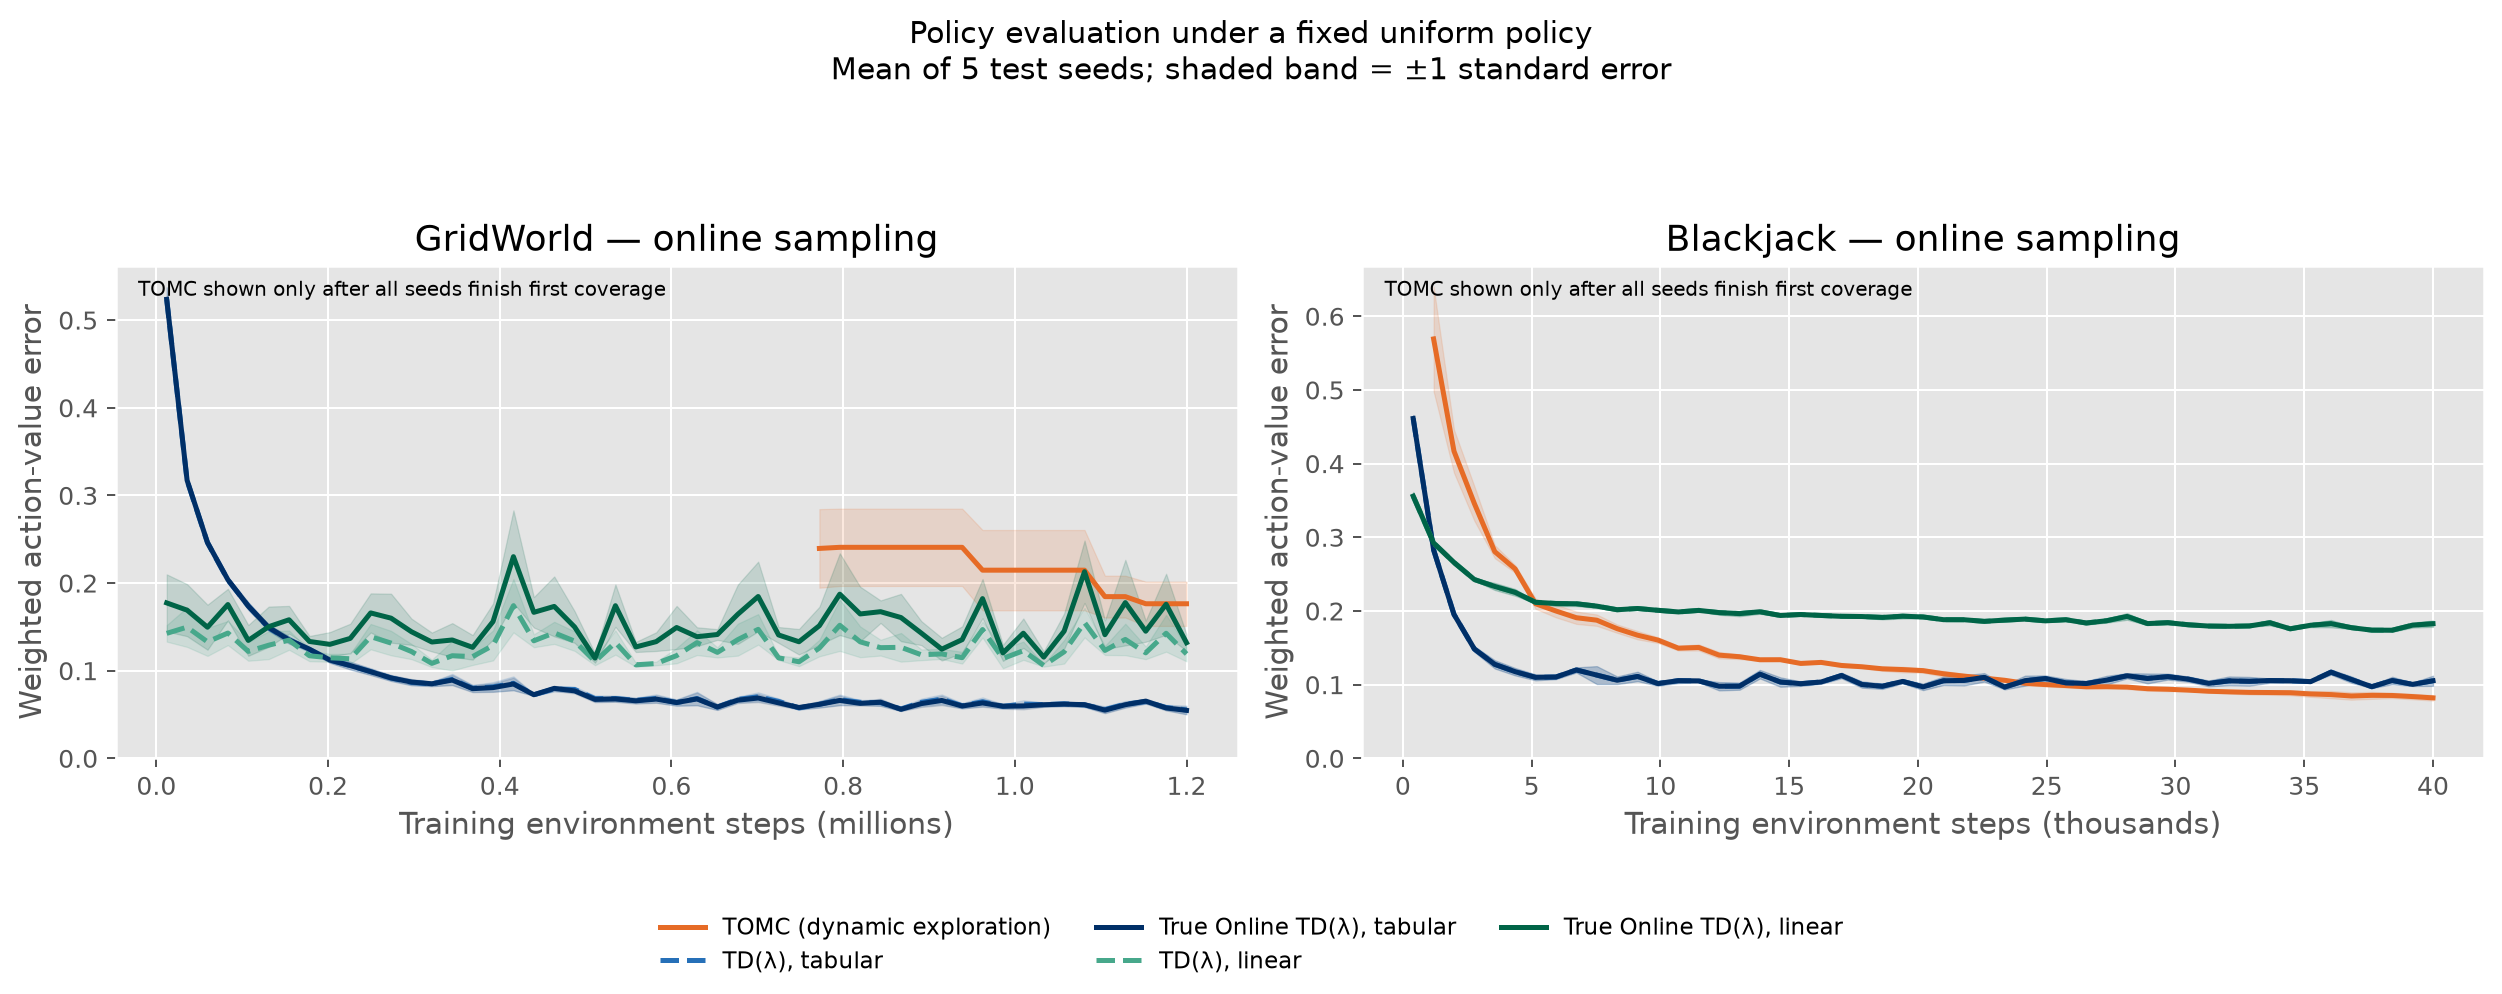

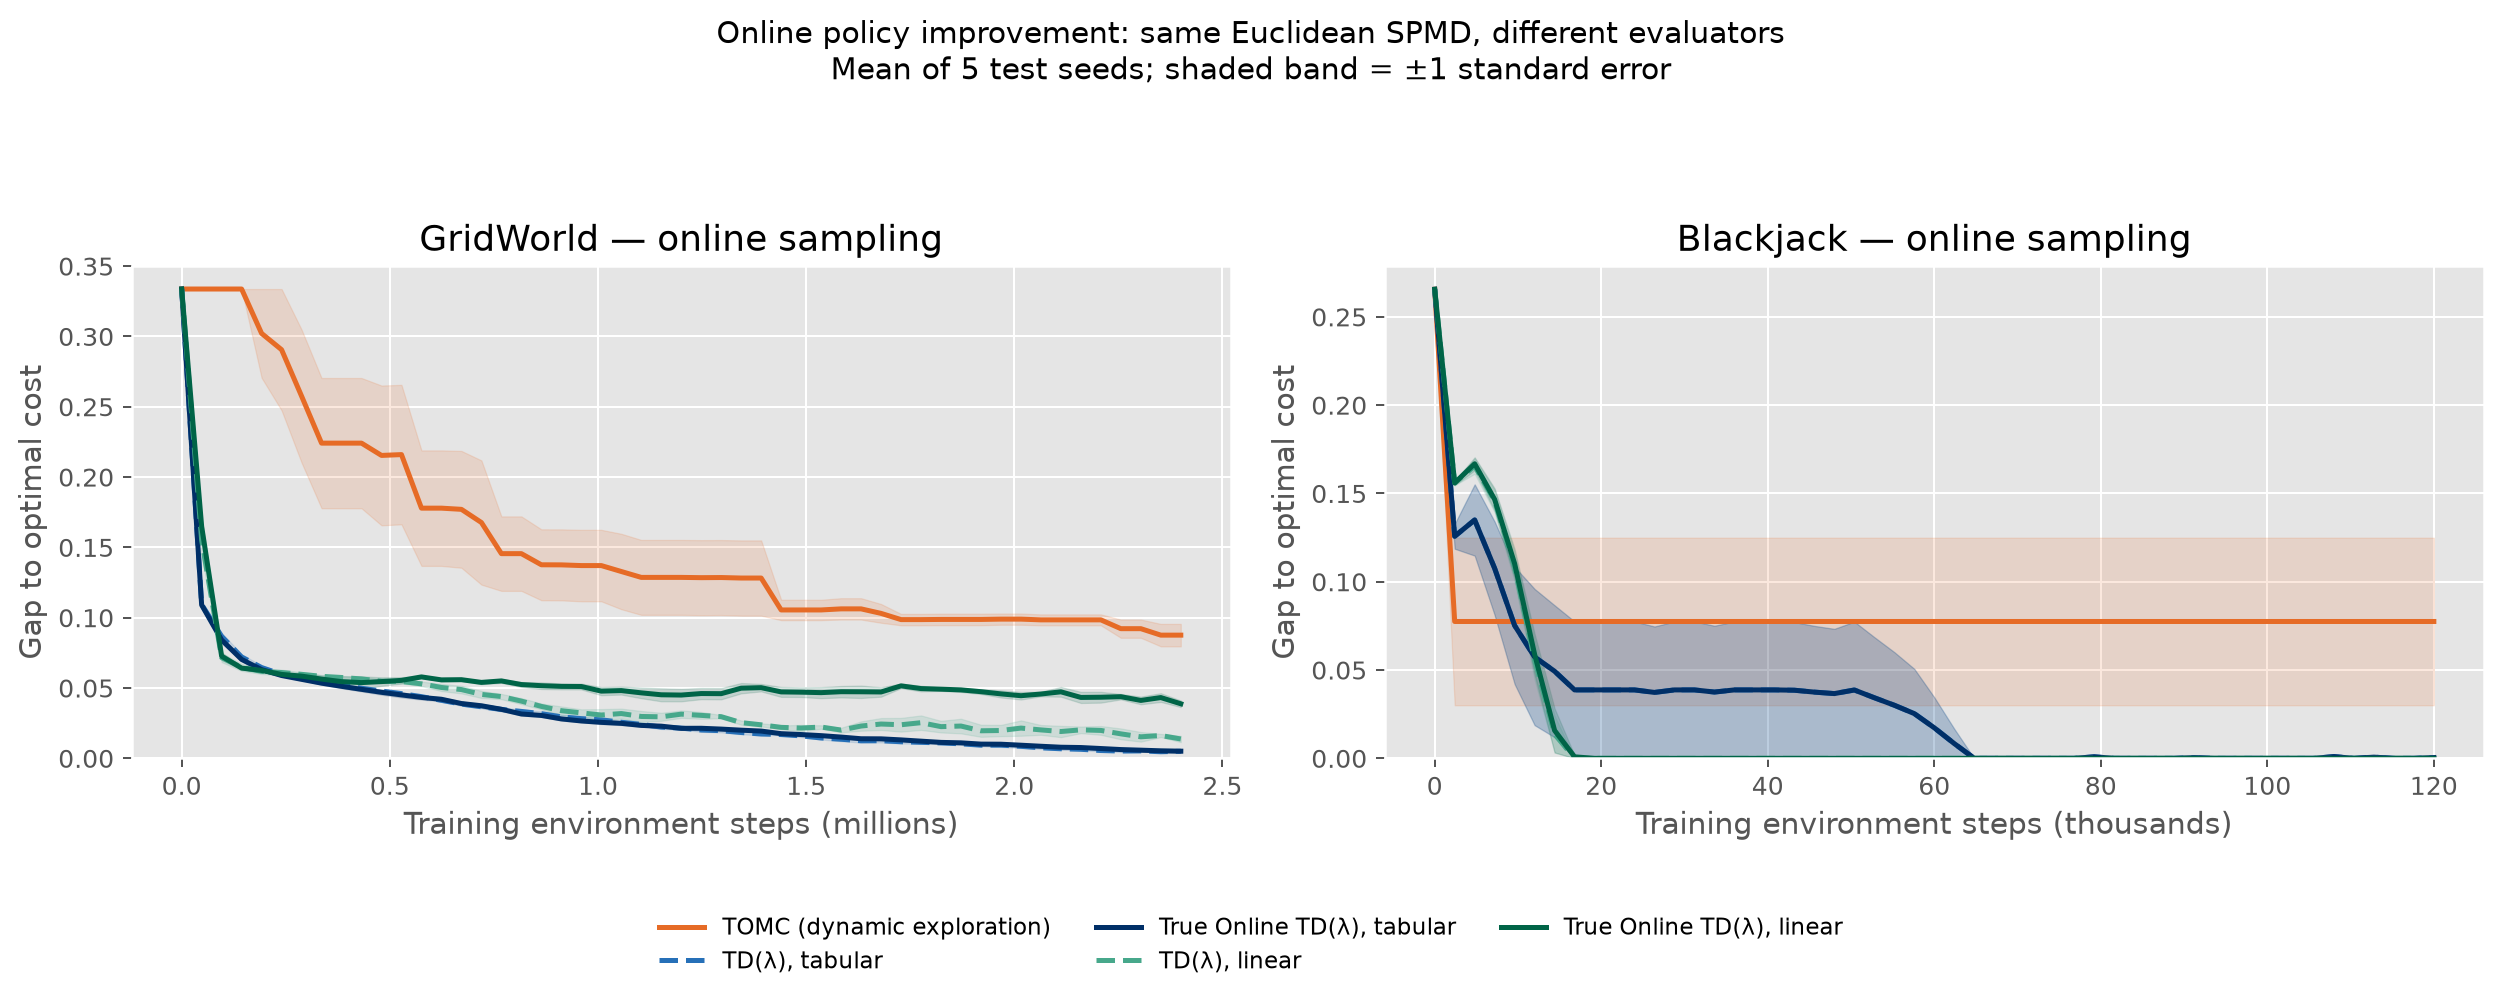

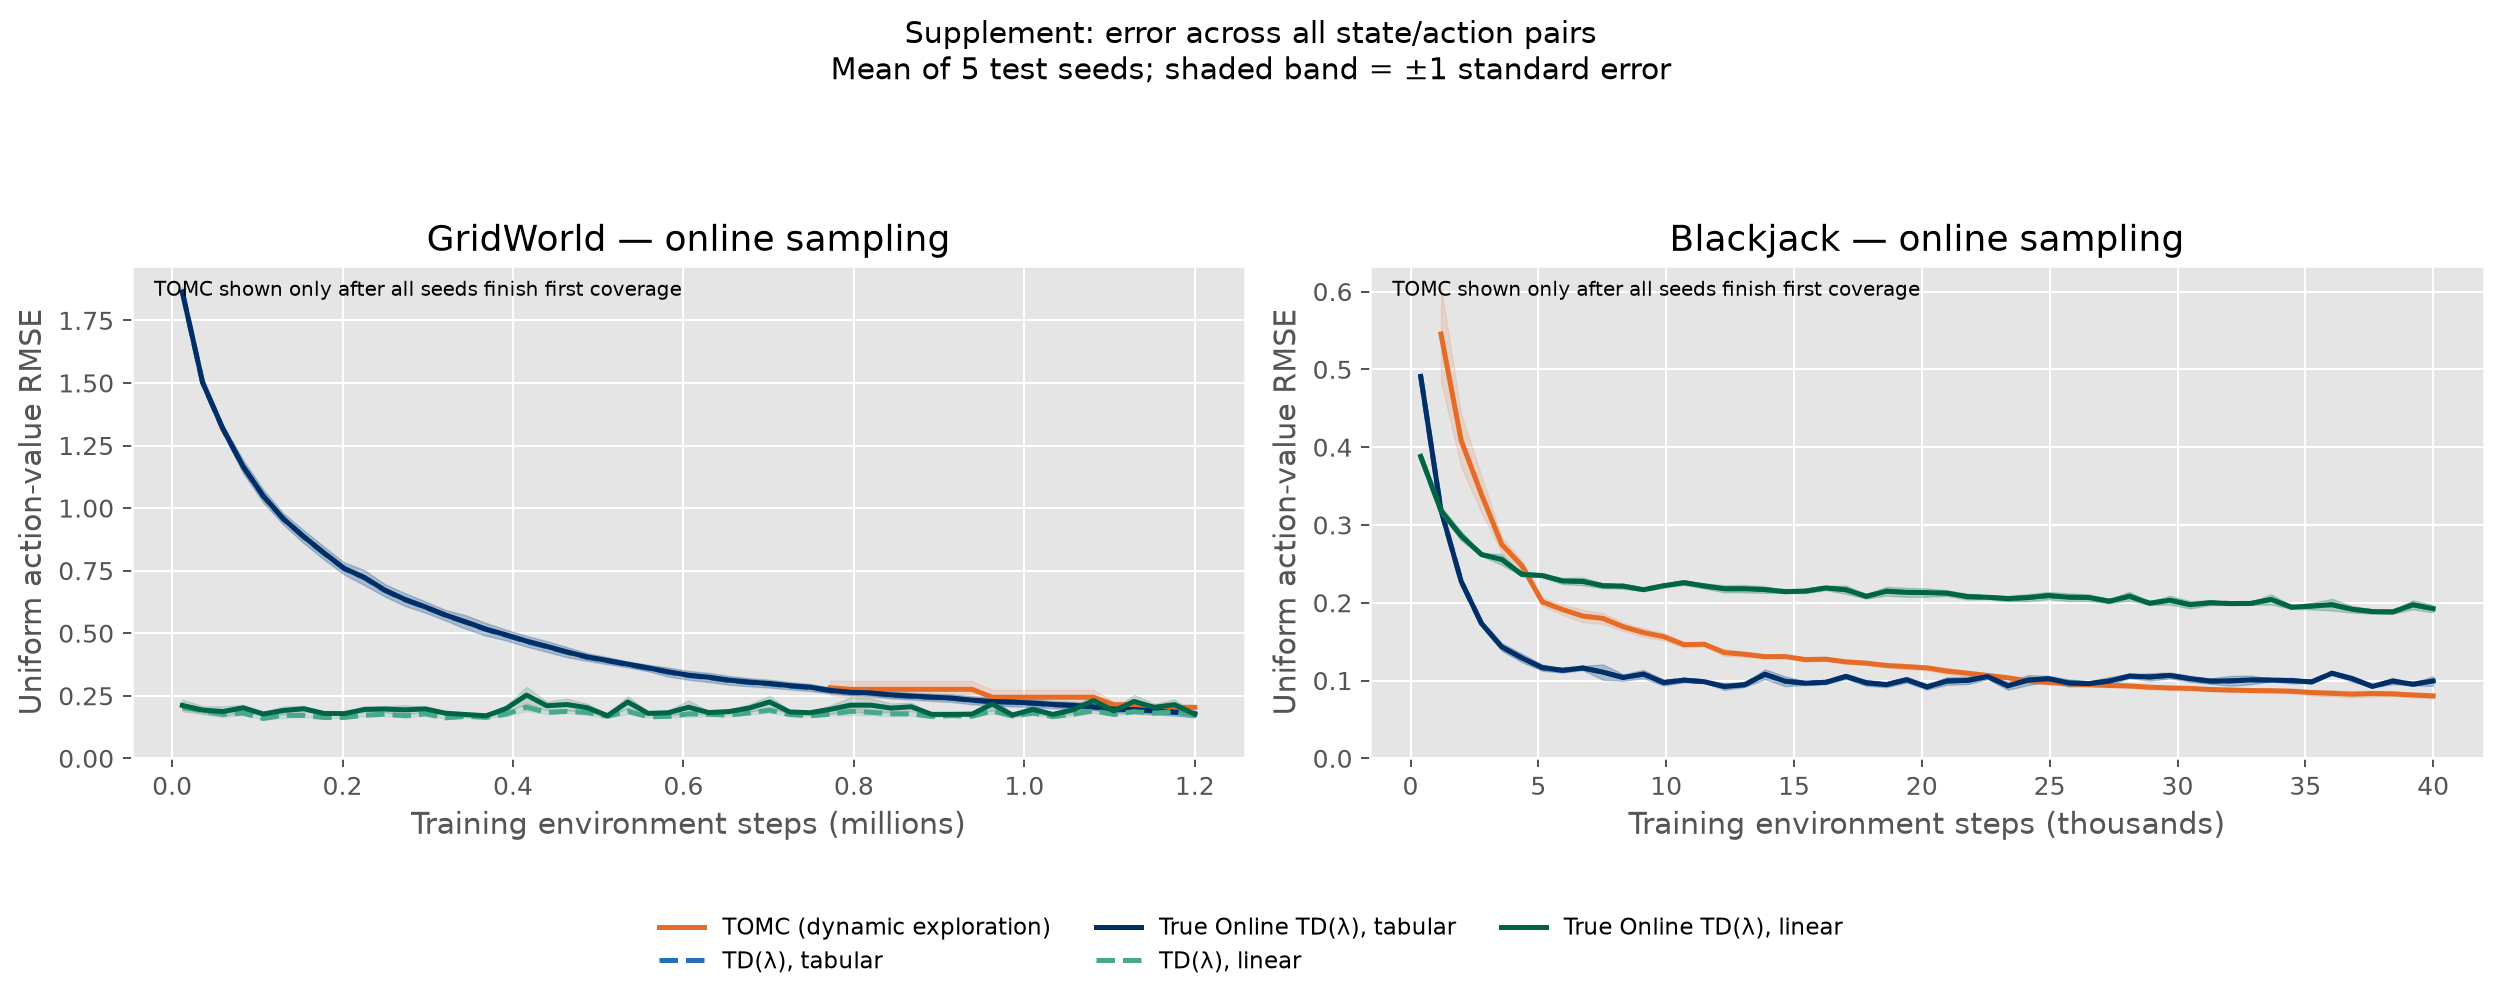

In [12]:
from IPython.display import Image, display
for name in ['policy_evaluation_error', 'policy_evaluation_policy_gap', 'policy_evaluation_uniform_error']:
    display(Image(filename=str(results / (name + '.png'))))


## What still needs to be said in the report

Report both improvements and failures. A compact linear representation can have approximation error even after many observations. A policy-gap improvement alone does not prove more accurate policy evaluation. Baseline coverage delays and unequal numbers of policy updates are part of this equal-observation comparison. The experiments are not a proof that True Online TD(λ) always beats ordinary TD(λ).

Use `POLICY_EVALUATION_FINDINGS.md` for the measured results and remaining project requirements; use `readme.md` for terminal commands.


## Measured observations

- **GridWorld evaluation:** tabular TD(λ) and True Online TD(λ) finish with almost identical weighted errors (0.05521 and 0.05472), below TOMC (0.17637). The observed difference between the two tabular TD methods is small relative to their standard-error bands.
- **GridWorld policy improvement:** tabular TD(λ) and True Online TD(λ) finish near a 0.0051 gap, compared with 0.08761 for TOMC. Ordinary linear TD finishes at 0.01377; true-online linear TD is worse here at 0.03880. The correction is not uniformly beneficial under these settings.
- **Blackjack evaluation:** TOMC finishes with the lowest weighted error (0.08208), compared with 0.10527 for either tabular TD method and about 0.18273 for the compact linear methods. Thus the enhancement does not beat TOMC on every evaluation problem.
- **Blackjack policy improvement:** both linear methods finish at zero gap at the chosen evaluation state `(8,3)`; both tabular TD methods average a 0.00044 gap. TOMC averages 0.07750, with two seeds ending at 0.19375. Accurate evaluation under a uniform policy and good control from one start state are different outcomes; zero start-state gap is not evidence of optimality at every state.
- **Overlapping Blackjack curves:** the tabular ordinary and true-online curves coincide. Player totals increase within a hand, so a tabular state/action pair is not revisited before the terminal trace reset; the true-online correction consequently vanishes for these trajectories. This agreement is consistent with the game structure.
- **Metric choice matters:** GridWorld's final uniform RMSE is 0.17078 for ordinary linear TD versus 0.17676 for ordinary tabular TD, reversing their ordering under visitation-weighted error. Keep the supplemental plot when discussing rarely visited states.

